# 03 · El exponente de Medellín

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

**Pregunta:** si la velocidad de un corredor sube un 10%, ¿cuánto suben los incidentes graves?

El modelo de Nilsson dice que los siniestros crecen como una potencia de la velocidad: **graves ∝ velocidad^β**.
β es el *exponente*. Aquí lo estimamos con datos de Medellín, con una **regresión binomial negativa**:
- unidad: corredor × hora × año (12 corredores de Google Traffic, 6:00–20:00, 2017–2019, D4);
- respuesta: incidentes graves (herido + muerto) de la base del ITM (D8), asignados al corredor con su geometría (D27);
- exposición: volumen de vehículos de cada corredor y hora (SIMM);
- controles: corredor y año (y franja u hora, D11).

Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [17]:
import os, sys, unicodedata, re, warnings
from pathlib import Path
from statsmodels.tools.sm_exceptions import ConvergenceWarning, HessianInversionWarning
for w in (ConvergenceWarning, HessianInversionWarning):
    warnings.filterwarnings("ignore", category=w)                # la convergencia se revisa en ajustar()

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from src.descarga import leer
from src.velocidad import CORREDORES, tiempo_viaje_gt
from src.seguridad import limpiar_itm
from src.corredores import geometria_corredores, asignar_corredor, _partes, _tokens_alias

# Los alias deben ser los confirmados por Johan (rama johan, commit "Alias en formato ITM confirmados con coordenadas")
assert CORREDORES["AUT_SUR"][1].startswith("CR 50"), "src/velocidad.py está desactualizado: une la rama johan y haz git pull"

pd.set_option("display.max_columns", 40)
Path("data/processed").mkdir(parents=True, exist_ok=True)
RAPIDAS = ["AV_REGIONAL", "AUT_NORTE", "AUT_SUR", "AV_PALMAS"]          # D18
NOMBRE = {cid: v[0] for cid, v in CORREDORES.items()}
warnings.filterwarnings("ignore", category=RuntimeWarning, module="statsmodels")
print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


In [2]:
# Nombres de columnas uniformes: minúscula, sin tildes, con guion bajo
def _arreglar_texto(s):
    for codif in ("latin-1", "cp1252"):
        try:
            return s.encode(codif).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return s

def normalizar_columnas(df):
    nuevas = []
    for c in df.columns:
        c = unicodedata.normalize("NFKD", _arreglar_texto(str(c))).encode("ascii", "ignore").decode()
        nuevas.append(re.sub(r"[^0-9a-z]+", "_", c.lower()).strip("_"))
    df.columns = nuevas
    return df

def numero(serie):
    return pd.to_numeric(serie.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def en_medellin(lat, lon):                         # D10: lo de fuera de la ciudad es faltante
    return (lat > 6.0) & (lat < 6.5) & (lon > -75.8) & (lon < -75.3)

## 1 · Tabla maestra (corredor × hora × año)
- Incidentes graves limpios con `limpiar_itm()` (Josué; D8 y D10).
- **Geometría y asignación a corredores** con `src/corredores.py` (D27): las estaciones del SIMM cortadas al tramo de Google Traffic; un incidente es del corredor si está a ≤ 50 m de su geometría (30 y 100 m como sensibilidad).
- Velocidad con `tiempo_viaje_gt()` de Johan; volumen del SIMM como exposición.

#### 1.1 Incidentes graves asignados a corredores (2017–2019, 6:00–20:00)

In [3]:
itm = limpiar_itm()                              # solo herido y muerto (D8); relleno a vacío (D10)
cat, rep_geo = geometria_corredores(itm)         # D27: geometría de los 12 corredores
asig = asignar_corredor(itm, cat)                # D27: corredor a ≤ 50 m, distancia y cruces ambiguos

asig["ano"] = pd.to_numeric(asig["anio"], errors="coerce")
asig["hora"] = pd.to_numeric(asig["hora"], errors="coerce")
graves = asig[asig["ano"].between(2017, 2019) & asig["hora"].between(6, 20)].copy()
graves["ano"] = graves["ano"].astype(int)

por_dir = graves["metodo_asignacion"] == "direccion"            # sin coordenadas: cuenta en todos los radios
for r in (30, 50, 100):
    graves[f"cor_{r}m"] = graves["corredor_cercano"].where(graves["dist_corredor_m"] <= r)
    graves.loc[por_dir, f"cor_{r}m"] = graves.loc[por_dir, "corredor_id"]
graves["cor_sin_cruces"] = graves["cor_50m"].where(~graves["ambiguo"].astype(bool))

print(f"Incidentes graves 2017–2019, 6:00–20:00: {len(graves):,}")
print(f"Asignados a un corredor (≤ 50 m o por dirección): {graves['cor_50m'].notna().sum():,} "
      f"({graves['cor_50m'].notna().mean() * 100:.1f}%)")
print(graves["metodo_asignacion"].value_counts().to_string())

limpiar_itm: coordenadas fuera de Medellín (pasan a vacío): 0
incidentes_limpios: 702540 leídas | eliminadas (sin fecha o sin gravedad): 0 | final: 702540 | sin coordenadas: 44785 | sin dirección: 15365
limpiar_itm: 702540 incidentes -> 403135 graves (se quitan 299405 de solo daños)
limpiar_itm: coordenadas repetidas más de 100 veces: 677 (138005 incidentes)
lat       lon       
6.276994  -75.572664    1553
6.265727  -75.575023    1131
6.260355  -75.573188     883
6.186616  -75.656601     823
6.273374  -75.592978     817
6.265181  -75.571703     765
6.248540  -75.580890     751
6.275406  -75.573746     707
6.269632  -75.576185     685
6.265556  -75.575333     685
6.270373  -75.573835     665
6.217069  -75.586457     664
6.303399  -75.561550     656
6.263626  -75.596980     643
6.268109  -75.576809     636
Incidentes graves 2017–2019, 6:00–20:00: 60,294
Asignados a un corredor (≤ 50 m o por dirección): 8,791 (14.6%)
metodo_asignacion
sin_asignar    51503
coordenadas     8790
direccion  

#### 1.2 La geometría de cada corredor
Longitud de la geometría frente a la del tramo de Google Traffic, y cómo se ubicó cada extremo (detalle en `docs/geometria_corredores.txt`).

In [4]:
g = rep_geo[["estaciones", "tramo_gt_km", "geometria_km", "hueco_max_m", "regla"]].copy()
g["cobertura_%"] = (g["geometria_km"] / g["tramo_gt_km"] * 100).round(0)
g.index = g.index.map(NOMBRE)
g

,estaciones,tramo_gt_km,geometria_km,hueco_max_m,regla,cobertura_%
corredor_id,,,,,,
Avenida 80,11,5.10,4.89,1774,los dos extremos ubicados con datos,96.0
Avenida 33,7,2.55,2.91,1546,los dos extremos ubicados con datos,114.0
Calle 30,4,2.90,2.90,1490,"un extremo ubicado; el otro, con la longitud d...",100.0
Avenida El Poblado,8,3.80,4.31,1224,los dos extremos ubicados con datos,113.0
Avenida San Juan,5,2.50,2.86,1512,los dos extremos ubicados con datos,114.0
Avenida Oriental,5,1.60,1.42,720,"un extremo ubicado; el otro, con la longitud d...",89.0
Avenida Guayabal,10,4.10,4.05,1490,los dos extremos ubicados con datos,99.0
Autopista Norte,9,5.30,5.19,1182,"un extremo ubicado; el otro, con la longitud d...",98.0
Autopista Sur,8,6.50,5.02,2088,"un extremo ubicado; el otro, con la longitud d...",77.0


#### 1.3 Incidentes por corredor y radio
Cuántos incidentes quedan en cada corredor según el radio, y cuántos están en un cruce con otro corredor (ambiguos: van al más cercano).

In [5]:
resumen = pd.DataFrame({f"≤{r} m": graves[f"cor_{r}m"].value_counts() for r in (30, 50, 100)})
resumen["ambiguos (≤50 m)"] = graves.loc[graves["ambiguo"].astype(bool), "cor_50m"].value_counts()
resumen["por dirección"] = graves.loc[por_dir, "corredor_id"].value_counts()
resumen = resumen.reindex(list(CORREDORES)).fillna(0).astype(int)
resumen.index = resumen.index.map(NOMBRE)
resumen

,≤30 m,≤50 m,≤100 m,ambiguos (≤50 m),por dirección
Avenida 80,617,779,1354,31,1
Avenida 33,417,667,1017,61,0
Calle 30,447,453,681,4,0
Avenida El Poblado,530,665,803,0,0
Avenida San Juan,693,776,1177,80,0
Avenida Oriental,661,794,1032,0,0
Avenida Guayabal,680,797,1165,0,0
Autopista Norte,1386,1960,2803,0,0
Autopista Sur,342,777,1200,11,0
Avenida Regional,511,578,1169,29,0


#### 1.4 Validación cruzada con los alias de Johan
¿La dirección del incidente nombra la vía del corredor asignado por coordenadas? En la Regional y Las Palmas se espera poco (no tienen número propio). En la Autopista Sur el alias está incompleto: en el norte del tramo la vía es la Carrera 62–63 (P4).

In [6]:
a = graves[graves["cor_50m"].notna() & (graves["metodo_asignacion"] == "coordenadas")].copy()
a["partes"] = _partes(a["direccion_normalizada"])
filas = []
for cid in CORREDORES:
    d, t = a[a["cor_50m"] == cid], _tokens_alias(cid)
    filas.append({"corredor": NOMBRE[cid], "asignados ≤50 m": len(d),
                  "% con el alias en la dirección": round(d["partes"].map(lambda ps: bool(t.intersection(ps))).mean() * 100, 1)
                  if t and len(d) else None})
pd.DataFrame(filas).set_index("corredor")

,asignados ≤50 m,% con el alias en la dirección
corredor,,
Avenida 80,778,68.0
Avenida 33,667,78.7
Calle 30,453,93.4
Avenida El Poblado,665,82.6
Avenida San Juan,776,94.8
Avenida Oriental,794,84.0
Avenida Guayabal,797,88.0
Autopista Norte,1960,69.4
Autopista Sur,777,46.3


#### 1.5 Velocidad por corredor, hora y año (Google Traffic, `tiempo_viaje_gt()`)

In [7]:
tv = tiempo_viaje_gt()
tv["ano"] = pd.to_datetime(tv["fecha"]).dt.year
tv = tv[tv["ano"].between(2017, 2019) & tv["hora"].between(6, 20) & (tv["velocidad_gt_kmh"] > 0)]
vel = tv.groupby(["corredor_id", "hora", "ano"])["velocidad_gt_kmh"].mean().rename("vel").reset_index()
print("Corredores con velocidad:", vel["corredor_id"].nunique(), "de", len(CORREDORES))
print("Faltan:", set(CORREDORES) - set(vel["corredor_id"]) or "ninguno")

Corredores con velocidad: 12 de 12
Faltan: ninguno


#### 1.6 Exposición: volumen por corredor y hora (SIMM)
El SIMM solo trae jul–ago 2020 (D21). Se usa el **perfil horario** de volumen de cada corredor, suponiendo que la forma del día se mantiene. Lo que sea constante por corredor lo absorbe el efecto fijo.

In [8]:
simm = normalizar_columnas(leer("velocidad_simm"))
simm["corredor"] = simm["corredor"].astype(str).str.strip()
simm_a_id = {v[2]: cid for cid, v in CORREDORES.items()}
s = simm[(simm["velocidad_km_h"] > 0) & (simm["velocidad_km_h"] < 150) & (simm["intensidad"] > 0)]
s = s.assign(corredor_id=s["corredor"].map(simm_a_id)).dropna(subset=["corredor_id"])
vol = (s[s["hora"].between(6, 20)].groupby(["corredor_id", "hora"])["intensidad"].mean()
         .rename("vol").reset_index())
print("Corredores con volumen:", vol["corredor_id"].nunique(), "de", len(CORREDORES))
print("Sin volumen:", set(CORREDORES) - set(vol["corredor_id"]) or "ninguno")

Corredores con volumen: 12 de 12
Sin volumen: ninguno


#### 1.7 Unir todo

In [9]:
def contar(col):
    return graves.dropna(subset=[col]).groupby([col, "hora", "ano"]).size() \
                 .rename_axis(["corredor_id", "hora", "ano"])

tabla = vel.merge(vol, on=["corredor_id", "hora"], how="inner")
for col, nombre in [("cor_50m", "graves"), ("cor_30m", "graves_30m"), ("cor_100m", "graves_100m"),
                   ("cor_sin_cruces", "graves_sin_cruces")]:
    tabla = tabla.merge(contar(col).rename(nombre).reset_index(), on=["corredor_id", "hora", "ano"], how="left")
    tabla[nombre] = tabla[nombre].fillna(0).astype(int)

tabla["log_vel"] = np.log(tabla["vel"])
tabla["franja"] = pd.cut(tabla["hora"], [5, 8, 16, 20], labels=["pico_am", "valle", "pico_pm"])
tabla["tipo"] = np.where(tabla["corredor_id"].isin(RAPIDAS), "rapida", "arteria")
tabla.to_csv("data/processed/tabla_maestra.csv", index=False)

print(f"Filas: {len(tabla)} (corredores: {tabla['corredor_id'].nunique()}, horas: {tabla['hora'].nunique()}, años: {tabla['ano'].nunique()})")
print(f"Incidentes graves en la tabla: {tabla['graves'].sum():,} · celdas con 0: {(tabla['graves'] == 0).mean() * 100:.1f}%")
print(f"Media {tabla['graves'].mean():.1f} · varianza {tabla['graves'].var():.1f} (si la varianza >> media: binomial negativa)")
tabla.head()

Filas: 540 (corredores: 12, horas: 15, años: 3)
Incidentes graves en la tabla: 8,791 · celdas con 0: 0.9%
Media 16.3 · varianza 121.1 (si la varianza >> media: binomial negativa)


,corredor_id,hora,ano,vel,vol,graves,graves_30m,graves_100m,graves_sin_cruces,log_vel,franja,tipo
0,AUT_NORTE,6,2017,42.012613,882.301382,70,49,102,70,3.737970,pico_am,rapida
1,AUT_NORTE,6,2018,43.740000,882.301382,61,39,89,61,3.778263,pico_am,rapida
2,AUT_NORTE,6,2019,44.833734,882.301382,78,52,102,78,3.802961,pico_am,rapida
3,AUT_NORTE,7,2017,42.044369,872.077419,90,63,118,90,3.738725,pico_am,rapida
4,AUT_NORTE,7,2018,45.981860,872.077419,65,40,92,65,3.828247,pico_am,rapida


### Conclusión
- **Tabla maestra:** 540 filas (12 corredores × 15 horas × 3 años), sin huecos. Todos los corredores tienen velocidad (Google Traffic) y volumen (SIMM).
- **Incidentes asignados:** de los 60.294 incidentes graves de 2017–2019 entre 6:00 y 20:00, **8.791 (14,6%) ocurrieron a 50 m o menos de alguno de los 12 corredores**. Casi todos se asignaron por coordenadas (8.790); por dirección, solo 1.
- **La Autopista Norte es el corredor con más incidentes graves:** 1.960, el 22% de los asignados. Le siguen Guayabal, Oriental, Av. 80, Autopista Sur y San Juan (entre 776 y 797 cada uno).
- **La geometría cubre bien el tramo medido** en 10 de los 12 corredores (89% a 114% de la longitud de Google Traffic). Las excepciones son la Autopista Sur (77%) y **Las Palmas (55%)**: sus estaciones del SIMM no cubren todo el tramo, y por eso Las Palmas solo tiene 101 incidentes.
- **La validación con las direcciones confirma la asignación:** en 8 de los 11 corredores con número propio, entre el 76% y el 95% de los incidentes asignados nombran la vía del corredor. Los más bajos se explican: la Autopista Sur (46%) tiene otro número en el norte del tramo (Carrera 62–63, P4), y la Av. 80 (68%) y la Autopista Norte (69%) recogen incidentes de sus vías laterales (Carrera 81 y Carrera 65).
- **El radio importa:** a 30 m quedan 6.641 incidentes y a 100 m, 13.424, el doble. Los cruces entre dos corredores son pocos: 216 (2,5%), sobre todo en San Juan y la Av. 33.
- **La varianza (121) es 7 veces la media (16,3):** los incidentes están sobredispersos, lo que anticipa que la binomial negativa será mejor que la Poisson (se prueba en 3.1).

### Decisión
- El conteo principal de incidentes graves es el de **50 m** (D27). Los de 30 y 100 m y la versión sin cruces entran como sensibilidad (4.3).
- Las Palmas se queda en el modelo, porque el efecto fijo de cada corredor absorbe su menor cobertura, pero se reporta como limitación. La prueba quitando un corredor a la vez (4.2) muestra si cambia el resultado.

## 2 · ¿Se ve la relación a simple vista?
Tasa = graves / volumen. Izquierda: todos los corredores. Derecha: **dentro de cada corredor** (se resta el promedio de cada uno), que es la comparación que hace el modelo.

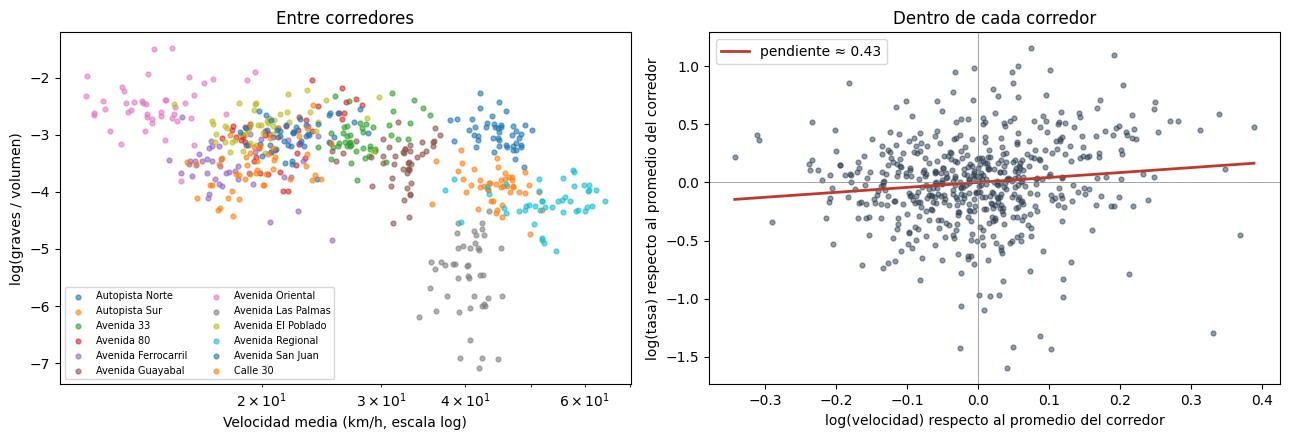

In [10]:
t = tabla.copy()
t["log_tasa"] = np.log((t["graves"] + 0.5) / t["vol"])
t["log_vel_c"] = t["log_vel"] - t.groupby("corredor_id")["log_vel"].transform("mean")
t["log_tasa_c"] = t["log_tasa"] - t.groupby("corredor_id")["log_tasa"].transform("mean")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for c, d in t.groupby("corredor_id"):
    ax1.scatter(d["vel"], d["log_tasa"], s=12, alpha=0.6, label=NOMBRE[c])
ax1.set_xscale("log"); ax1.set_xlabel("Velocidad media (km/h, escala log)"); ax1.set_ylabel("log(graves / volumen)")
ax1.set_title("Entre corredores"); ax1.legend(fontsize=7, ncol=2)

ax2.scatter(t["log_vel_c"], t["log_tasa_c"], s=12, alpha=0.5, color="#2c3e50")
pend, inter = np.polyfit(t["log_vel_c"], t["log_tasa_c"], 1)
xs = np.linspace(t["log_vel_c"].min(), t["log_vel_c"].max(), 50)
ax2.plot(xs, inter + pend * xs, color="#c0392b", lw=2, label=f"pendiente ≈ {pend:.2f}")
ax2.axhline(0, color="grey", lw=0.5); ax2.axvline(0, color="grey", lw=0.5)
ax2.set_xlabel("log(velocidad) respecto al promedio del corredor")
ax2.set_ylabel("log(tasa) respecto al promedio del corredor")
ax2.set_title("Dentro de cada corredor"); ax2.legend()
plt.tight_layout(); plt.show()

### Conclusión
- **Entre corredores, la relación es negativa:** los corredores más rápidos (Regional, Calle 30, Autopistas) tienen menos incidentes graves por vehículo que las arterias lentas (Oriental, Ferrocarril, El Poblado). No es un efecto de la velocidad: son vías distintas. Las arterias tienen semáforos, cruces y peatones; las vías rápidas, flujo continuo. Comparar corredores entre sí llevaría a una conclusión falsa.
- **Dentro de cada corredor, la relación se invierte y es positiva:** en un mismo corredor, las horas más rápidas tienen más incidentes graves por vehículo. La pendiente bruta es **0,43**: un 10% más de velocidad se asocia con unos 4% más de incidentes graves por vehículo.
- La dispersión es grande y la pendiente está muy por debajo de Nilsson (≈ 2). Es lo que se anticipaba: dentro de un corredor, las horas rápidas son las de menos congestión, y la hora se mezcla con la velocidad.
- Las Palmas (gris) queda muy abajo porque su geometría cubre solo el 55% del tramo; el efecto fijo absorbe ese nivel.

### Decisión
- El modelo usa **efectos fijos por corredor**: solo compara cada corredor consigo mismo, que es la comparación de la derecha.
- Se espera un exponente bajo. La sección 3 dice si se mantiene al controlar por año (modelo A) y por hora (modelos B y C).

## 3 · El modelo
$\log E[\text{graves}] = \log(\text{volumen}) + \beta \cdot \log(\text{velocidad}) + \text{corredor} + \text{año}$

β es el exponente: si la velocidad sube 10%, los graves se multiplican por $1{,}1^\beta$.

⚠ Dentro de un corredor, las horas rápidas suelen ser las de menos congestión (y menos conflicto). Por eso β puede salir bajo o negativo: no sería que la velocidad proteja, sino que la hora y la congestión se mezclan con ella.

#### 3.1 ¿Poisson o binomial negativa?

In [11]:
def ajustar(formula, d, y="graves", avisar=True):
    """Binomial negativa que arranca desde la Poisson. Si no converge, Poisson con errores robustos."""
    f = formula.replace("graves", y, 1)
    pois = smf.poisson(f, data=d, exposure=d["vol"]).fit(disp=0, maxiter=300)
    try:
        r = smf.negativebinomial(f, data=d, exposure=d["vol"]).fit(
            start_params=np.append(pois.params, 0.1), disp=0, maxiter=500)
        if r.mle_retvals.get("converged") and np.isfinite(r.bse).all():
            return r
    except Exception:
        pass
    if avisar:
        print(f"⚠ La binomial negativa no convergió ({f}): se usa Poisson con errores robustos")
    return smf.poisson(f, data=d, exposure=d["vol"]).fit(disp=0, maxiter=300, cov_type="HC0")

f_A = "graves ~ log_vel + C(corredor_id) + C(ano)"
pois = smf.poisson(f_A, data=tabla, exposure=tabla["vol"]).fit(disp=0, maxiter=200)
nb_A = ajustar(f_A, tabla)

lr = 2 * (nb_A.llf - pois.llf)
print("Modelo ajustado:", type(nb_A.model).__name__)
print(f"alpha (sobredispersión): {nb_A.params.get('alpha', 0):.3f}")
print(f"Prueba de razón de verosimilitud: LR = {lr:.1f}, p = {stats.chi2.sf(lr, 1) / 2:.2g}")
print(f"AIC Poisson: {pois.aic:.0f} · AIC binomial negativa: {nb_A.aic:.0f} (menor = mejor)")

Modelo ajustado: NegativeBinomial
alpha (sobredispersión): 0.044
Prueba de razón de verosimilitud: LR = 120.6, p = 2.4e-28
AIC Poisson: 3345 · AIC binomial negativa: 3226 (menor = mejor)


#### 3.2 El exponente
- **Modelo A:** corredor + año.
- **Modelo B:** + franja (pico_am 6–8, valle 9–16, pico_pm 17–20; las mismas del costo en tiempo).
- **Modelo C:** + hora exacta (D11). Es el más exigente: solo usa cómo cambia la velocidad de *cada* corredor respecto al patrón horario común.

In [12]:
f_B = f_A + " + C(franja)"
f_C = f_A + " + C(hora)"
nb_B, nb_C = ajustar(f_B, tabla), ajustar(f_C, tabla)

def fila(nombre, res, var="log_vel"):
    b, (lo, hi) = res.params[var], res.conf_int().loc[var]
    return {"modelo": nombre, "beta": b, "IC95_inf": lo, "IC95_sup": hi, "p": res.pvalues[var],
            "+10% velocidad → graves": f"{(1.1 ** b - 1) * 100:+.1f}%", "AIC": res.aic}

exponente = pd.DataFrame([fila("A · corredor + año", nb_A), fila("B · + franja", nb_B),
                          fila("C · + hora (D11)", nb_C)]).set_index("modelo")
exponente.round(3)

,beta,IC95_inf,IC95_sup,p,+10% velocidad → graves,AIC
modelo,,,,,,
A · corredor + año,0.522,0.260,0.783,0.000,+5.1%,3226.355
B · + franja,-0.249,-0.508,0.011,0.060,-2.3%,3088.384
C · + hora (D11),-0.267,-0.560,0.027,0.075,-2.5%,3074.782


#### 3.3 ¿Es distinto en las vías rápidas? (D18)
**Modelo D:** un β para las vías rápidas y otro para las arterias, con los mismos controles del modelo A.

In [13]:
f_D = "graves ~ log_vel:C(tipo) + C(corredor_id) + C(ano)"
nb_D = ajustar(f_D, tabla)
v_rap, v_art = "log_vel:C(tipo)[rapida]", "log_vel:C(tipo)[arteria]"
dif = nb_D.params[v_rap] - nb_D.params[v_art]
ee = np.sqrt(nb_D.cov_params().loc[v_rap, v_rap] + nb_D.cov_params().loc[v_art, v_art]
             - 2 * nb_D.cov_params().loc[v_rap, v_art])
print(f"¿Difieren? diferencia = {dif:.2f}, p = {2 * stats.norm.sf(abs(dif / ee)):.3f}")
pd.DataFrame([fila("D · vías rápidas", nb_D, v_rap), fila("D · arterias", nb_D, v_art)]).set_index("modelo").round(3)

¿Difieren? diferencia = -1.34, p = 0.000


,beta,IC95_inf,IC95_sup,p,+10% velocidad → graves,AIC
modelo,,,,,,
D · vías rápidas,-0.520,-1.053,0.012,0.056,-4.8%,3209.983
D · arterias,0.823,0.533,1.113,0.000,+8.2%,3209.983


In [19]:
f_E = "graves ~ log_vel:C(franja) + C(corredor_id) + C(ano) + C(hora)"
nb_E = ajustar(f_E, tabla)
filas = [fila(f"E · {fr}", nb_E, f"log_vel:C(franja)[{fr}]") for fr in ["pico_am", "valle", "pico_pm"]]
print("¿El efecto de la velocidad cambia según la franja? (modelo E, con la hora como control)")
pd.DataFrame(filas).set_index("modelo").round(3)

¿El efecto de la velocidad cambia según la franja? (modelo E, con la hora como control)


,beta,IC95_inf,IC95_sup,p,+10% velocidad → graves,AIC
modelo,,,,,,
E · pico_am,-0.695,-1.070,-0.321,0.000,-6.4%,3062.827
E · valle,-0.420,-0.719,-0.121,0.006,-3.9%,3062.827
E · pico_pm,-0.356,-0.692,-0.019,0.038,-3.3%,3062.827


#### 3.4 Comparación con la literatura

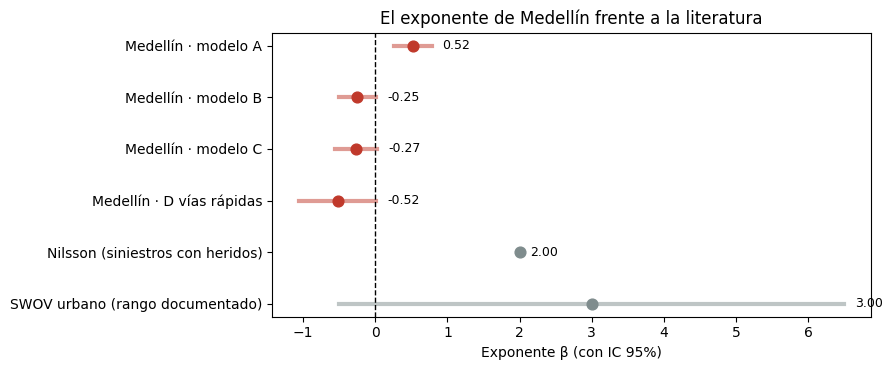

In [14]:
ref = pd.DataFrame({
    "fuente": ["Medellín · modelo A", "Medellín · modelo B", "Medellín · modelo C", "Medellín · D vías rápidas",
               "Nilsson (siniestros con heridos)", "SWOV urbano (rango documentado)"],
    "beta": [nb_A.params["log_vel"], nb_B.params["log_vel"], nb_C.params["log_vel"], nb_D.params[v_rap], 2.0, 3.0],
    "inf": [*exponente["IC95_inf"], nb_D.conf_int().loc[v_rap, 0], 2.0, -0.5],
    "sup": [*exponente["IC95_sup"], nb_D.conf_int().loc[v_rap, 1], 2.0, 6.5],
})
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = ["#c0392b"] * 4 + ["#7f8c8d"] * 2
for i, r in ref.iterrows():
    ax.plot([r["inf"], r["sup"]], [i, i], color=colores[i], lw=3, alpha=0.5)
    ax.scatter(r["beta"], i, color=colores[i], s=60, zorder=3)
    ax.text(r["sup"] + 0.15, i, f"{r['beta']:.2f}", va="center", fontsize=9)
ax.axvline(0, ls="--", color="black", lw=1)
ax.set_yticks(range(len(ref)), ref["fuente"]); ax.invert_yaxis()
ax.set_xlabel("Exponente β (con IC 95%)")
ax.set_title("El exponente de Medellín frente a la literatura")
plt.tight_layout(); plt.show()

### Conclusión
- **La binomial negativa es mejor que la Poisson:** hay sobredispersión (α = 0,044; razón de verosimilitud LR = 120,6, p ≈ 10⁻²⁸; AIC 3.226 frente a 3.345).
- **Sin controlar por la hora, el exponente es positivo:** β = 0,52 (IC 95%: 0,26 a 0,78). Un 10% más de velocidad se asocia con un 5% más de incidentes graves. Es la cuarta parte de lo que dice Nilsson (≈ 2).
- **Al controlar por la franja o por la hora, el efecto desaparece:** β = −0,25 (−0,51 a 0,01) y −0,27 (−0,56 a 0,03), sin distinguirse de cero. El AIC prefiere claramente estos modelos (3.088 y 3.075 frente a 3.226): la hora explica mucho más que la velocidad.
- **Por qué:** dentro de un corredor, la velocidad cambia durante el día sobre todo por la congestión. Las horas rápidas son también las de menos tráfico, otros viajes y otras condiciones, y eso se mezcla con la velocidad. Además, el volumen por hora viene del SIMM de 2020 (pandemia), y controlar por la hora corrige los errores en la forma del día.
- **La comparación por tipo de vía (modelo D)** da β = +0,82 en las arterias y −0,52 en las vías rápidas (diferencia significativa, p < 0,001). Pero no controla por la hora, así que no se interpreta como efecto de la velocidad.
- **Lo que esto significa:** con datos de tráfico diario no se puede medir lo que hace un tope de velocidad. Nilsson describe qué pasa cuando baja la velocidad media con el mismo tráfico; nuestros datos solo tienen velocidades que cambian porque cambia el tráfico.

### Decisión
- **El exponente de Medellín no se usa como valor central del Monte Carlo.** Se reporta como lo que es: la evidencia directa disponible en Medellín, que no permite separar la velocidad de la congestión.
- El Monte Carlo usa un **rango**: el piso lo ponen los datos de Medellín (≈ 0 para los incidentes graves por este notebook, y 0,64 para la letalidad por la cuarentena, notebook 04); el techo, la literatura (Nilsson). El resultado de Bogotá sirve como prueba de sensatez.
- En el notebook final, el paso 8 usa la segunda versión del texto: *"en Medellín la evidencia directa es débil, y por eso no apostamos a un solo número: simulamos con un rango"*.

## 4 · ¿Qué tan estable es el exponente?

#### 4.1 Bootstrap por corredor
Con solo 12 corredores, el intervalo del modelo puede quedarse corto. Se re-sortean corredores con reemplazo 500 veces y se re-estima β. Esta distribución es la que usará el Monte Carlo.

Modelo A: 500 re-estimaciones · mediana 0.55 · IC 95% [0.09, 0.99]
Modelo C: 500 re-estimaciones · mediana -0.25 · IC 95% [-0.63, 0.25]


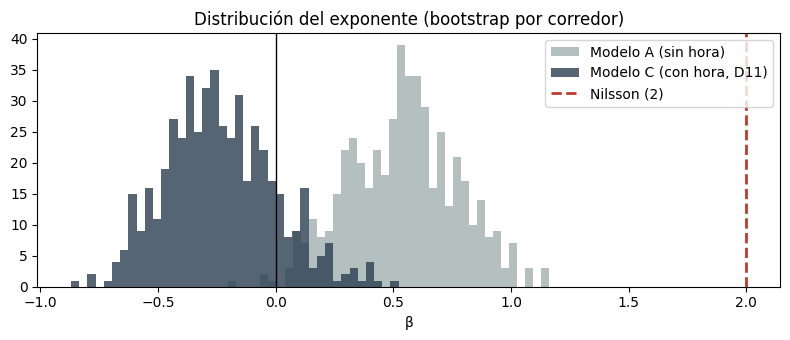

In [18]:
rng = np.random.default_rng(2026)
corredores = tabla["corredor_id"].unique()
boot = {"A": [], "C": []}
for _ in range(500):
    muestra = rng.choice(corredores, size=len(corredores), replace=True)
    bs = pd.concat([tabla[tabla["corredor_id"] == c].assign(corredor_id=f"{c}_{k}") for k, c in enumerate(muestra)])
    for nombre, f in (("A", f_A), ("C", f_C)):
        try:
            boot[nombre].append(ajustar(f, bs, avisar=False).params["log_vel"])
        except Exception:
            pass
boot = {k: np.array(v) for k, v in boot.items()}
np.save("data/processed/betas_bootstrap.npy", boot["C"])        # D11: la hora es control
np.save("data/processed/betas_bootstrap_A.npy", boot["A"])
betas = boot["C"]

for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"Modelo {k}: {len(v)} re-estimaciones · mediana {np.median(v):.2f} · IC 95% [{lo:.2f}, {hi:.2f}]")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(boot["A"], bins=40, color="#95a5a6", alpha=0.7, label="Modelo A (sin hora)")
ax.hist(boot["C"], bins=40, color="#2c3e50", alpha=0.8, label="Modelo C (con hora, D11)")
ax.axvline(2.0, color="#c0392b", ls="--", lw=2, label="Nilsson (2)")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("β"); ax.set_title("Distribución del exponente (bootstrap por corredor)"); ax.legend()
plt.tight_layout(); plt.show()

#### 4.2 Dejando un corredor afuera
¿Algún corredor solo determina el resultado?

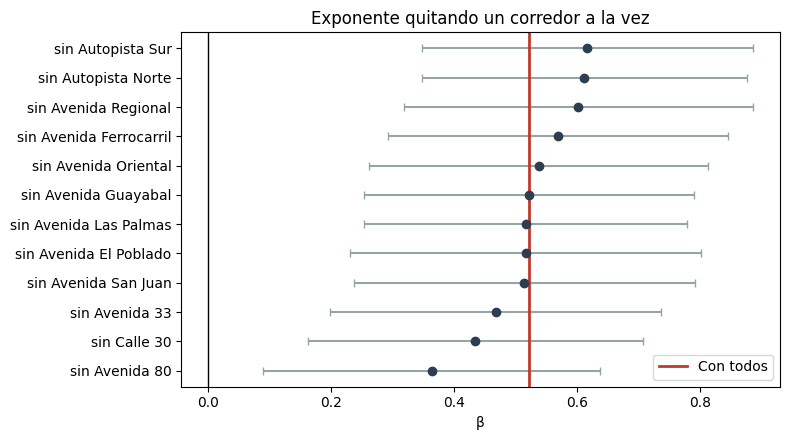

In [23]:
loo = []
for c in corredores:
    d = tabla[tabla["corredor_id"] != c]
    r = ajustar(f_A, d)
    loo.append({"sin": NOMBRE[c], "beta": r.params["log_vel"],
                "inf": r.conf_int().loc["log_vel", 0], "sup": r.conf_int().loc["log_vel", 1]})
loo = pd.DataFrame(loo).sort_values("beta")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(loo["beta"], range(len(loo)), xerr=[loo["beta"] - loo["inf"], loo["sup"] - loo["beta"]],
            fmt="o", color="#2c3e50", ecolor="#95a5a6", capsize=3)
ax.axvline(nb_A.params["log_vel"], color="#c0392b", lw=2, label="Con todos")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(loo)), "sin " + loo["sin"])
ax.set_xlabel("β"); ax.set_title("Exponente quitando un corredor a la vez"); ax.legend()
plt.tight_layout(); plt.show()

#### 4.3 ¿Depende de cómo se asignan los incidentes?
El mismo modelo A contando los incidentes a ≤ 30 m, ≤ 50 m (principal) y ≤ 100 m del corredor, y sin los cruces entre dos corredores.

In [24]:
radios = pd.DataFrame([fila(nombre, ajustar(f_A, tabla, y)) for nombre, y in
                       [("A · ≤30 m", "graves_30m"), ("A · ≤50 m (principal)", "graves"),
                        ("A · ≤100 m", "graves_100m"), ("A · ≤50 m sin cruces", "graves_sin_cruces")]]).set_index("modelo")
radios.round(3)

,beta,IC95_inf,IC95_sup,p,+10% velocidad → graves,AIC
modelo,,,,,,
A · ≤30 m,0.619,0.341,0.896,0.0,+6.1%,2985.263
A · ≤50 m (principal),0.522,0.260,0.783,0.0,+5.1%,3226.355
A · ≤100 m,0.471,0.245,0.698,0.0,+4.6%,3556.224
A · ≤50 m sin cruces,0.532,0.268,0.795,0.0,+5.2%,3205.840


### Conclusión
- **El bootstrap por corredor muestra que el intervalo del modelo se quedaba corto.** Con el modelo A, el IC 95% pasa de 0,26–0,78 a **0,09–0,99**: el resultado depende bastante de qué corredores entran.
- **Controlar por la hora mueve todo el exponente.** Con el modelo C (D11), el bootstrap da una mediana de **−0,25 (IC 95%: −0,63 a 0,25)**. Las dos distribuciones casi no se tocan, y ninguna se acerca a Nilsson (2).
- **La asignación no cambia el resultado:** con el modelo A, β va de 0,47 (100 m) a 0,62 (30 m), y sin los cruces entre corredores es 0,53.
- **Ningún corredor decide el resultado por sí solo:** quitando uno a la vez, β va de 0,36 (sin la Av. 80) a 0,62 (sin la Autopista Sur), siempre positivo y lejos de 2.
- **En resumen:** lo que determina el exponente no es cómo se asignan los incidentes ni qué corredores entran, sino si se controla la hora del día, que en estos datos es casi lo mismo que la congestión.

### Decisión
- Para el Monte Carlo se usa la distribución del bootstrap del **modelo C** (`betas_bootstrap.npy`), **cortada en 0**. Un β negativo diría que bajar la velocidad aumenta los incidentes, lo que no tiene sentido físico: es la congestión colándose.
- Ese es el **piso** del rango. El techo es Nilsson (D26).

## 5 · ¿Qué significa para las vías rápidas?
Reducción esperada de incidentes graves si la velocidad media baja a 50 km/h donde hoy la supera (solo como lectura del exponente; el cálculo completo, hora por hora y con incertidumbre, es el Monte Carlo).

In [25]:
b_mod, b_lo, b_hi = nb_A.params["log_vel"], np.percentile(betas, 2.5), np.percentile(betas, 97.5)

def reduccion(d, b):
    peso = d["graves"] + 0.5
    return (1 - np.average((np.minimum(d["vel"], 50) / d["vel"]) ** b, weights=peso)) * 100

filas = []
for c, d in tabla[tabla["corredor_id"].isin(RAPIDAS)].groupby("corredor_id"):
    filas.append({"corredor": NOMBRE[c], "vel_media": d["vel"].mean(), "% horas sobre 50": (d["vel"] > 50).mean() * 100,
                  "graves_por_año": d["graves"].sum() / d["ano"].nunique(),
                  "reducción_Medellín_%": reduccion(d, b_mod),
                  "IC_bootstrap_%": f"{reduccion(d, b_lo):.1f} a {reduccion(d, b_hi):.1f}",
                  "reducción_Nilsson_%": reduccion(d, 2.0)})
lect = pd.DataFrame(filas).set_index("corredor")
lect.round(2)

,vel_media,% horas sobre 50,graves_por_año,reducción_Medellín_%,IC_bootstrap_%,reducción_Nilsson_%
corredor,,,,,,
Autopista Norte,44.66,2.22,653.33,0.00,-0.0 a 0.0,0.01
Autopista Sur,44.37,4.44,259.00,0.05,-0.1 a 0.0,0.17
Avenida Las Palmas,40.37,0.00,33.67,0.00,0.0 a 0.0,0.00
Avenida Regional,53.03,73.33,192.67,4.24,-5.6 a 2.1,14.52


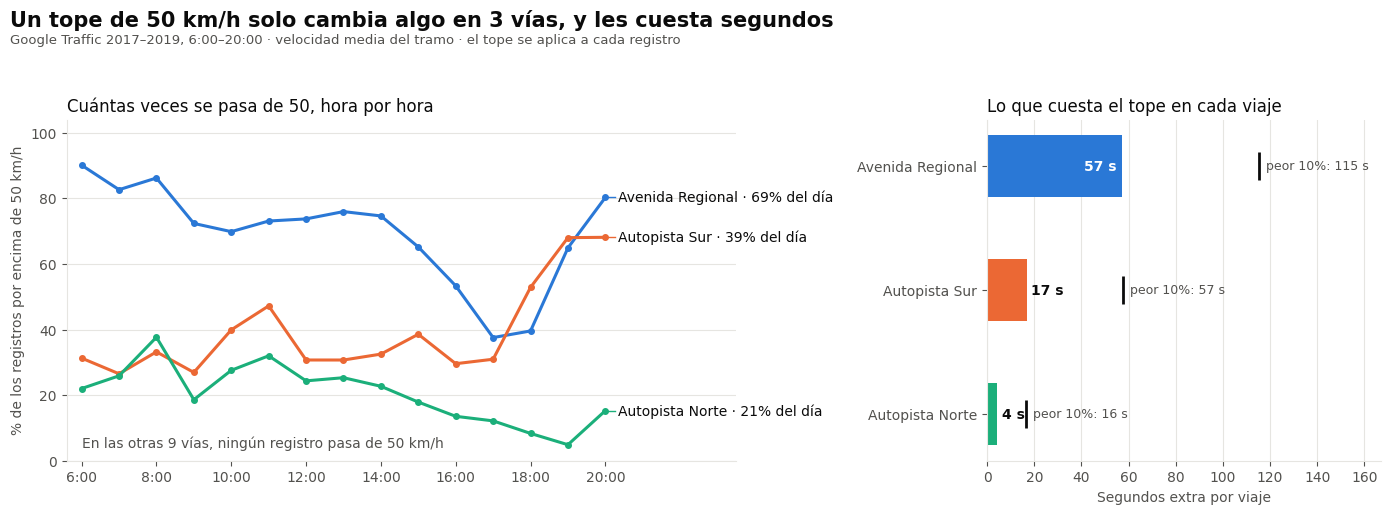

,% registros > 50,segundos extra (media),segundos extra (peor 10%)
corredor_id,,,
Avenida Regional,68.9,57.0,115.2
Autopista Sur,39.3,16.8,57.5
Autopista Norte,20.5,4.3,16.4
Avenida Las Palmas,0.1,0.0,0.0
Avenida 80,0.0,0.0,0.0
Avenida 33,0.0,0.0,0.0
Avenida Guayabal,0.0,0.0,0.0
Avenida Ferrocarril,0.0,0.0,0.0
Avenida Oriental,0.0,0.0,0.0


In [30]:
# --- 5.2 · ¿Dónde y cuándo actúa un tope de 50 km/h? ---
tv = tiempo_viaje_gt()
tv["ano"] = pd.to_datetime(tv["fecha"]).dt.year
tv = tv[tv["ano"].between(2017, 2019) & (tv["velocidad_gt_kmh"] > 0)].copy()
L_km = cat.set_index("corredor_id")["longitud_km"]
v = tv["velocidad_gt_kmh"]
tv["sobre_50"] = v > 50
tv["seg_extra"] = (tv["corredor_id"].map(L_km) * 3600 * (1 / np.minimum(v, 50) - 1 / v)).clip(lower=0)

resumen_tope = tv.groupby("corredor_id").agg(pct_sobre_50=("sobre_50", "mean"), seg_media=("seg_extra", "mean"),
                                             seg_p90=("seg_extra", lambda s: s.quantile(0.9)))
resumen_tope["pct_sobre_50"] *= 100
resumen_tope = resumen_tope.sort_values("pct_sobre_50", ascending=False)
actua = resumen_tope.index[resumen_tope["pct_sobre_50"] >= 1].tolist()       # vías donde el tope cambia algo
otras = len(resumen_tope) - len(actua)

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e6e5e1"
color = {c: COLORES[i % len(COLORES)] for i, c in enumerate(actua)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})
por_hora = tv[tv["corredor_id"].isin(actua)].pivot_table(index="hora", columns="corredor_id", values="sobre_50", aggfunc="mean") * 100
for c in actua:
    s = por_hora[c]
    ax1.plot(s.index, s.values, color=color[c], lw=2.2, marker="o", ms=4)
# nombres al final de cada línea, separados al menos 8 puntos para que no se encimen
fin = sorted(((por_hora[c].iloc[-1], c) for c in actua), reverse=True)
pos = []
for val, c in fin:
    pos.append(min(val, pos[-1] - 8) if pos else val)
for (val, c), yy in zip(fin, pos):
    ax1.plot([20, 20.25], [val, yy], color=color[c], lw=1)
    ax1.text(20.35, yy, f"{NOMBRE[c]} · {resumen_tope.loc[c, 'pct_sobre_50']:.0f}% del día",
             va="center", fontsize=10, color=TINTA)
ax1.set_xlim(5.6, 23.5); ax1.set_ylim(0, 104)
ax1.set_xticks(range(6, 21, 2), [f"{h}:00" for h in range(6, 21, 2)])
ax1.set_ylabel("% de los registros por encima de 50 km/h", color=TINTA_2)
ax1.set_title("Cuántas veces se pasa de 50, hora por hora", loc="left", fontsize=12, color=TINTA)
ax1.text(6, 4, f"En las otras {otras} vías, ningún registro pasa de 50 km/h", fontsize=10, color=TINTA_2)

y = np.arange(len(actua))[::-1]
ax2.barh(y, resumen_tope.loc[actua, "seg_media"], color=[color[c] for c in actua], height=0.5)
ax2.set_xlim(0, resumen_tope.loc[actua, "seg_p90"].max() * 1.45)
ax2.scatter(resumen_tope.loc[actua, "seg_p90"], y, marker="|", s=400, color=TINTA, lw=2, zorder=3)
for yi, c in zip(y, actua):
    m, p = resumen_tope.loc[c, "seg_media"], resumen_tope.loc[c, "seg_p90"]
    dentro = m > ax2.get_xlim()[1] * 0.15
    ax2.text(m - 2 if dentro else m + 2, yi, f"{m:.0f} s", va="center", ha="right" if dentro else "left",
             fontsize=10, color="white" if dentro else TINTA, weight="bold")
    ax2.text(p + 3, yi, f"peor 10%: {p:.0f} s", va="center", fontsize=9, color=TINTA_2)
ax2.set_yticks(y, [NOMBRE[c] for c in actua])
ax2.set_xlabel("Segundos extra por viaje", color=TINTA_2)
ax2.set_title("Lo que cuesta el tope en cada viaje", loc="left", fontsize=12, color=TINTA)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2)
ax1.grid(axis="y", color=GRILLA, lw=0.8); ax2.grid(axis="x", color=GRILLA, lw=0.8)
ax1.set_axisbelow(True); ax2.set_axisbelow(True)
fig.suptitle(f"Un tope de 50 km/h solo cambia algo en {len(actua)} vías, y les cuesta segundos",
             x=0.01, ha="left", fontsize=15, color=TINTA, weight="bold")
fig.text(0.01, 0.915, "Google Traffic 2017–2019, 6:00–20:00 · velocidad media del tramo · el tope se aplica a cada registro",
         fontsize=9.5, color=TINTA_2)
plt.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()

tabla_tope = resumen_tope.round(1).rename(columns={"pct_sobre_50": "% registros > 50",
                                                  "seg_media": "segundos extra (media)", "seg_p90": "segundos extra (peor 10%)"})
tabla_tope.index = tabla_tope.index.map(NOMBRE)
tabla_tope

In [29]:
# --- 5 · Reducción esperada de incidentes graves con un tope de 50 (registro por registro) ---
peso = tabla.groupby(["corredor_id", "hora"])["graves"].mean()          # cuándo ocurren los incidentes
tv["peso"] = pd.MultiIndex.from_frame(tv[["corredor_id", "hora"]]).map(peso)
tv["factor"] = np.minimum(tv["velocidad_gt_kmh"], 50) / tv["velocidad_gt_kmh"]

def reduccion(d, b):
    return (1 - np.average(d["factor"] ** b, weights=d["peso"])) * 100

piso = np.median(np.maximum(betas, 0))                                  # bootstrap del modelo C, cortado en 0
filas = []
for c in ["AV_REGIONAL", "AUT_SUR", "AUT_NORTE", "AV_PALMAS"]:
    d = tv[(tv["corredor_id"] == c) & tv["peso"].notna()]
    filas.append({"corredor": NOMBRE[c],
                  "% registros > 50": d["sobre_50"].mean() * 100,
                  "graves por año": tabla.loc[tabla["corredor_id"] == c, "graves"].sum() / 3,
                  f"Medellín, modelo C (β={piso:.2f})": reduccion(d, piso),
                  f"Medellín, modelo A (β={nb_A.params['log_vel']:.2f})": reduccion(d, nb_A.params["log_vel"]),
                  "Nilsson heridos (β=2)": reduccion(d, 2),
                  "Nilsson muertos (β=4)": reduccion(d, 4)})
lect = pd.DataFrame(filas).set_index("corredor").round(1)
print("Reducción esperada (%) de incidentes graves con un tope de 50 km/h, 6:00–20:00")
lect

Reducción esperada (%) de incidentes graves con un tope de 50 km/h, 6:00–20:00


,% registros > 50,graves por año,"Medellín, modelo C (β=0.00)","Medellín, modelo A (β=0.52)",Nilsson heridos (β=2),Nilsson muertos (β=4)
corredor,,,,,,
Avenida Regional,68.9,192.7,0.0,6.5,21.2,34.8
Autopista Sur,39.3,259.0,0.0,1.9,6.5,11.4
Autopista Norte,20.5,653.3,0.0,0.7,2.3,4.3
Avenida Las Palmas,0.1,33.7,0.0,0.0,0.0,0.0


### Conclusión
- **Un tope de 50 km/h solo cambia algo en 3 vías:** la Regional (el 69% de los registros pasa de 50), la Autopista Sur (39%) y la Autopista Norte (20,5%). En las otras 9 vías, incluida Las Palmas, prácticamente ningún registro pasa de 50 entre las 6:00 y las 20:00.
- **En la Regional se pasa de 50 todo el día:** desde el 90% de los registros a las 6:00 hasta el 38% en el pico de la tarde. En la Autopista Sur el exceso crece en la noche (68% a las 19:00 y 20:00), y en la Autopista Norte es más alto en la mañana (38% a las 8:00).
- **El costo es de segundos:** 57 s por viaje en la Regional (115 s en el peor 10%), 17 s en la Autopista Sur (58 s) y 4 s en la Autopista Norte (16 s). En la congestión no cuesta nada, porque nadie llega a 50: un tope fijo ya se comporta como uno que cambia con la hora.
- **El beneficio depende de cuánto pesa la velocidad.** Con la literatura (Nilsson), en la Regional los incidentes graves bajarían un 21% y los mortales un 35%, dentro del rango de Bogotá (−22% a −37%). En la Autopista Sur bajarían un 6,5% y un 11%, y en la Autopista Norte, un 2,3% y un 4%. Con los datos de Medellín, el efecto va de 0 (modelo C, con la hora como control) a −6,5% en la Regional (modelo A).
- **Son las vías donde más se muere:** la Autopista Norte, la Autopista Sur y la Regional concentran el 49% de los muertos en los 12 corredores (143 de 294, 2019–2024, D30).
- **La Regional es la vía donde el tope más rinde:** tiene el mayor exceso de velocidad, la mayor reducción esperada y un costo de menos de un minuto por viaje.
- Google Traffic mide la velocidad media del tramo y solo de 6:00 a 20:00. El exceso en un punto concreto de la vía es mayor: el SIMM, que mide en un punto, da cerca del 20% sobre 50 a cualquier hora.

### Decisión
- **D29:** el tope de 50 km/h se evalúa en la Regional, la Autopista Sur y la Autopista Norte. Las Palmas sale de la evaluación diurna; su noche queda pendiente de la velocidad nocturna (SIMM).
- **D28:** el Monte Carlo simula esas 3 vías con el exponente entre el piso de Medellín (modelo C, cortado en 0) y Nilsson, y usa como línea base los muertos del Distrito por corredor (D17, D30). El rango de Bogotá (−22% a −37%) sirve como prueba de sensatez.
- Estas cifras son una lectura del exponente, solo de 6:00 a 20:00. Las vidas salvadas con su intervalo salen del Monte Carlo.
- La gráfica de la sección 5.2 es la del **paso 7 del guion** ("Medellín tiene dos velocidades") y la base del eje de costo de la gráfica "segundos contra vidas" (paso 11).

## 6 · Resumen

**Pregunta.** Si la velocidad de un corredor sube, ¿cuánto suben los incidentes graves? Y con eso, ¿dónde serviría un tope de 50 km/h?

**Método**
- Una regresión binomial negativa sobre una tabla de corredor × hora × año: 12 corredores, de 6:00 a 20:00, entre 2017 y 2019 (540 filas).
- La respuesta son los 8.791 incidentes graves a 50 m o menos de cada corredor, asignados por su geometría (D27).
- El volumen del SIMM entra como exposición, y el corredor, el año y la hora, como controles.
- Para medir la incertidumbre: bootstrap por corredor (500 repeticiones), prueba quitando un corredor a la vez y prueba con distintos radios de asignación.

**Resultados**
1. **Sin controlar la hora, el exponente es 0,52:** un 10% más de velocidad, un 5% más de incidentes graves. Es la cuarta parte de lo que dice Nilsson (2).
2. **Con la hora como control, el efecto desaparece:** β = −0,27 (bootstrap: −0,63 a 0,25). Dentro de un corredor, la velocidad cambia durante el día por la congestión, y estos datos no pueden separar las dos cosas.
3. **El resultado es robusto:** no cambia con el radio de asignación (30, 50 o 100 m), sin los cruces entre corredores ni quitando cualquier corredor. Lo que lo mueve es solo controlar o no la hora.
4. **No se justifica un límite distinto por hora:** en ninguna franja más velocidad se asocia con más incidentes graves (modelo E). Al contrario, más congestión trae más incidentes, sobre todo en el pico de la mañana.
5. **Un tope de 50 solo cambia algo en 3 vías:** la Regional (69% de los registros sobre 50; 57 s por viaje), la Autopista Sur (39%; 17 s) y la Autopista Norte (20,5%; 4 s). En las otras 9, incluida Las Palmas, nadie pasa de 50 de día.
6. **Son las vías donde más se muere:** las tres concentran el 49% de los muertos en los 12 corredores (2019–2024).
7. **Con la literatura, la Regional es donde más rinde:** sus incidentes mortales bajarían un 35%, dentro del rango de Bogotá (−22% a −37%), a cambio de menos de un minuto por viaje.

**Qué se usa después**
- El **Monte Carlo** simula la Regional, la Autopista Sur y la Autopista Norte (D29). El exponente va en un rango (D28): el piso es el bootstrap del modelo C, cortado en 0 (`data/processed/betas_bootstrap.npy`), y el techo, Nilsson (2 para heridos, 4 para muertos). La prueba de sensatez es Bogotá.
- En el **notebook final**, el paso 8 usa la versión del texto para un resultado débil (*"en Medellín la evidencia directa es débil, y por eso no apostamos a un solo número: simulamos con un rango"*), y la gráfica de la sección 5.2 va en el paso 7.

**Limitaciones**
- La velocidad de Google Traffic es la media del tramo y solo cubre de 6:00 a 20:00. La noche no se puede evaluar con esta fuente.
- El volumen por hora viene del SIMM de julio y agosto de 2020, en plena pandemia.
- Las estaciones del SIMM están separadas 1–2 km: la geometría une los puntos con rectas, y Las Palmas solo tiene el 55% de su tramo cubierto.
- **La limitación de fondo:** los datos no tienen variación de velocidad con el mismo tráfico, que es justo lo que produce un tope. Por eso el efecto del tope se toma de la literatura y de Bogotá, no de este modelo.